# FIT5212 Assignment 1: Semi-Structured Data Analysis

**Student Name**: Akshat Dawange
**Student ID**: 34611266

This notebook is divided into two major sections as per the assignment requirements:

- **Part 1: Text Classification**
- **Part 2: Topic Modelling with LDA**

## Part 1: Text Classification

### Objective
The goal of this section is to classify research articles into the 'Computational Linguistics' category using their `Title` and `Abstract` fields. The task includes 8 configurations based on:

- Input: Title vs Abstract
- Model: Logistic Regression vs RNN
- Training size: 1000 vs Full training set

Reported Accuracy, Precision, Recall, F1-Score, and PR Curves for all models.


# Part 1 : Text Classification

## Importing Necessary Libraries

Importing the libraries which will be needed for the execution

In [1]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

Setting up the NLTK library for our specified usage

In [2]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\aksha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Text Pre-Processing

Defining a function for Pre-Processing of the Textual data. Includes steps such as:
1. Changing text to lower case
2. Regular expression to remove the characters which are not letters
3. Tokenization
4. Stemming

In [3]:
def preprocess_text_fast(text):
    text = text.lower()  # lowercase
    text = re.sub(r'[^a-z\s]', '', text)  # remove non-letters
    tokens = text.split()  # tokenize
    tokens = [stemmer.stem(word) for word in tokens if word not in stop_words and len(word) > 2]
    return " ".join(tokens)

## Loading the Datasets

- train_df -> Data used for training 
- dev_df -> Validation Dataset
- test_df -> Data used for testing the model

In [4]:
train_df = pd.read_csv('D:\\Codes\\Python\\Semi Structured Data Analysis\\Assignment1\\train_set.csv')
dev_df = pd.read_csv('D:\\Codes\\Python\\Semi Structured Data Analysis\\Assignment1\\dev_set.csv')
test_df = pd.read_csv('D:\\Codes\\Python\\Semi Structured Data Analysis\\Assignment1\\test_set.csv')

## Checking if the data has loaded correctly

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217058 entries, 0 to 217057
Data columns (total 5 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   title                     217058 non-null  object
 1   abstract                  217058 non-null  object
 2   HumanComputerInteraction  217058 non-null  int64 
 3   ComputationalLinguistics  217058 non-null  int64 
 4   MachineLearning           217058 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 8.3+ MB


In [6]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27133 entries, 0 to 27132
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   title                     27133 non-null  object
 1   abstract                  27133 non-null  object
 2   HumanComputerInteraction  27133 non-null  int64 
 3   ComputationalLinguistics  27133 non-null  int64 
 4   MachineLearning           27133 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 1.0+ MB


In [7]:
dev_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27132 entries, 0 to 27131
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   title                     27132 non-null  object
 1   abstract                  27132 non-null  object
 2   HumanComputerInteraction  27132 non-null  int64 
 3   ComputationalLinguistics  27132 non-null  int64 
 4   MachineLearning           27132 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 1.0+ MB


## Applying Pre-Processing Function

Generating new columns `clean_title` and `clean_abstract` from the existing `Title` and `Abstract` columns across all the data files after Pre-Processing 

Using `tqdm` to track the progress of the execution

In [8]:
tqdm.pandas()

train_df["clean_title"] = train_df["title"].progress_apply(preprocess_text_fast)
train_df["clean_abstract"] = train_df["abstract"].progress_apply(preprocess_text_fast)

dev_df["clean_title"] = dev_df["title"].progress_apply(preprocess_text_fast)
dev_df["clean_abstract"] = dev_df["abstract"].progress_apply(preprocess_text_fast)

test_df["clean_title"] = test_df["title"].progress_apply(preprocess_text_fast)
test_df["clean_abstract"] = test_df["abstract"].progress_apply(preprocess_text_fast)

100%|██████████| 27133/27133 [00:45<00:00, 590.69it/s]


Exploring the class distribution

C:\Users\aksha\AppData\Local\Temp\ipykernel_8256\3613571152.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=label_df, x="Class", y="Count", palette="coolwarm")


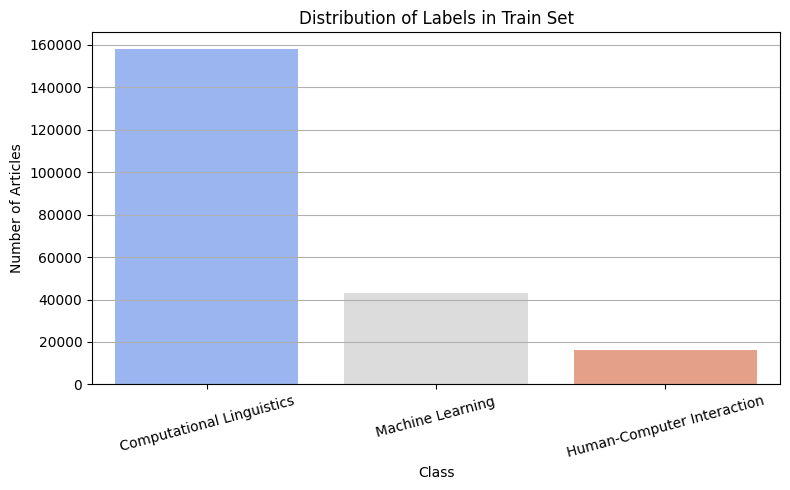

In [9]:
label_counts = {
    'Computational Linguistics': train_df["ComputationalLinguistics"].sum(),
    'Machine Learning': train_df["MachineLearning"].sum(),
    'Human-Computer Interaction': train_df["HumanComputerInteraction"].sum()
}

label_df = pd.DataFrame.from_dict(label_counts, orient='index', columns=['Count']).reset_index()
label_df.columns = ['Class', 'Count']

plt.figure(figsize=(8, 5))
sns.barplot(data=label_df, x="Class", y="Count", palette="coolwarm")
plt.title("Distribution of Labels in Train Set")
plt.ylabel("Number of Articles")
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

## Model Building

Libraries used for modeling

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, precision_recall_curve, average_precision_score

Using the training set to train the model and validation set to tune the hyper parameters

In [11]:
train_small = train_df.head(1000)
X_train = train_small["clean_abstract"]
y_train = train_small["ComputationalLinguistics"]

X_dev = dev_df["clean_abstract"]
y_dev = dev_df["ComputationalLinguistics"]

Transforming raw text into numerical vectors using TF-IDF 

In [12]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)

Initializing and Fitting the Logistic Regression model

In [13]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [14]:
y_pred = model.predict(X_dev_tfidf)
y_prob = model.predict_proba(X_dev_tfidf)[:, 1]

In [15]:
print("🔍 Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

🔍 Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.8098    0.2740    0.4094      7490
           1     0.7789    0.9755    0.8662     19642

    accuracy                         0.7818     27132
   macro avg     0.7944    0.6247    0.6378     27132
weighted avg     0.7874    0.7818    0.7401     27132

✅ Accuracy: 0.7818074598260357


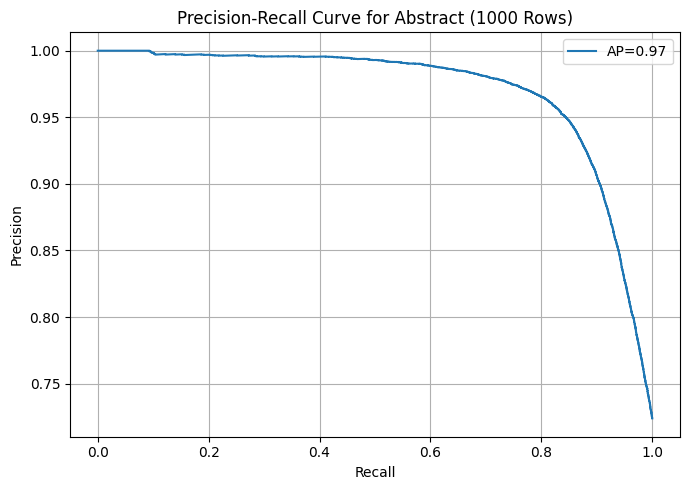

In [16]:
precision, recall,_ = precision_recall_curve(y_dev, y_prob)
avg_precision = average_precision_score(y_dev, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'AP={avg_precision:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Abstract (1000 Rows)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [17]:
X_train_full = train_df["clean_abstract"]
y_train_full = train_df["ComputationalLinguistics"]

In [19]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train_full)
X_dev_tfidf = vectorizer.transform(X_dev)

In [20]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train_full)

LogisticRegression(max_iter=1000)

In [21]:
y_pred = model.predict(X_dev_tfidf)
y_prob = model.predict_proba(X_dev_tfidf)[:, 1]

In [22]:
print("🔍 Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

🔍 Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.7968    0.7794    0.7880      7490
           1     0.9166    0.9242    0.9204     19642

    accuracy                         0.8842     27132
   macro avg     0.8567    0.8518    0.8542     27132
weighted avg     0.8835    0.8842    0.8838     27132

✅ Accuracy: 0.8842326404245909


In [23]:
precision, recall, _ = precision_recall_curve(y_dev, y_prob)
avg_precision = average_precision_score(y_dev, y_prob)

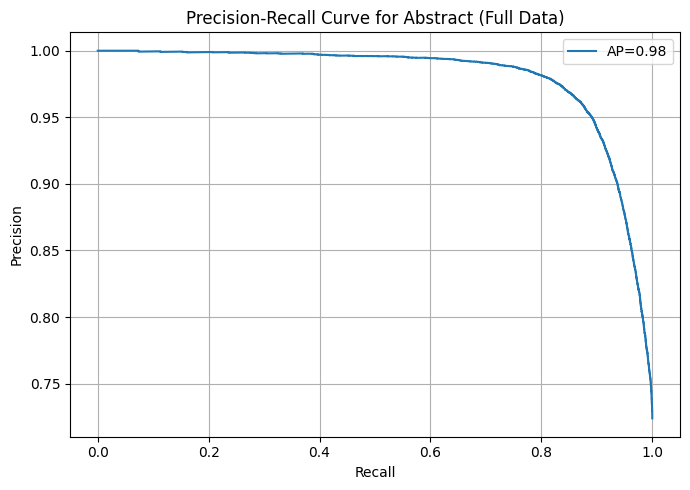

In [24]:
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'AP={avg_precision:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Abstract (Full Data)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [25]:
train_small = train_df.head(1000)
X_train = train_small["clean_title"]
y_train = train_small["ComputationalLinguistics"]

X_dev = dev_df["clean_title"]
y_dev = dev_df["ComputationalLinguistics"]

In [26]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)

In [27]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [28]:
y_pred = model.predict(X_dev_tfidf)
y_prob = model.predict_proba(X_dev_tfidf)[:, 1]

In [29]:
print("🔍 Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

🔍 Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.7340    0.1547    0.2556      7490
           1     0.7522    0.9786    0.8506     19642

    accuracy                         0.7512     27132
   macro avg     0.7431    0.5667    0.5531     27132
weighted avg     0.7472    0.7512    0.6864     27132

✅ Accuracy: 0.7511794191360754


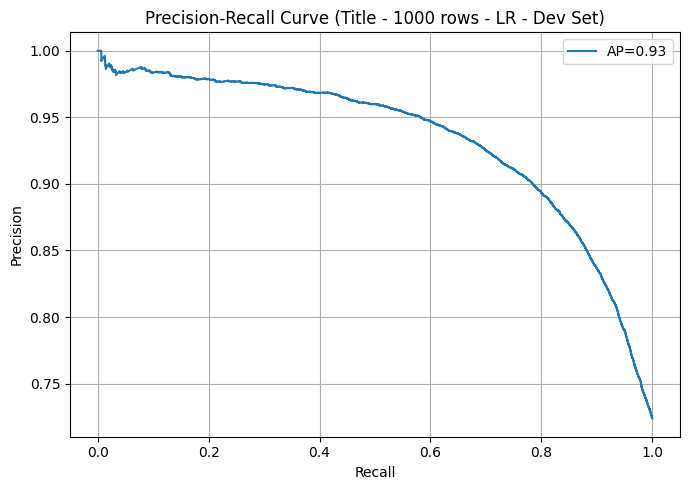

In [30]:
precision, recall, _ = precision_recall_curve(y_dev, y_prob)
avg_precision = average_precision_score(y_dev, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'AP={avg_precision:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Title - 1000 rows - LR - Dev Set)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

In [31]:
X_train = train_df["clean_title"]
y_train = train_df["ComputationalLinguistics"]

In [32]:
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)

In [33]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [34]:
y_pred = model.predict(X_dev_tfidf)
y_prob = model.predict_proba(X_dev_tfidf)[:, 1]

In [35]:
print("🔍 Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

🔍 Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.7708    0.7047    0.7363      7490
           1     0.8910    0.9201    0.9053     19642

    accuracy                         0.8606     27132
   macro avg     0.8309    0.8124    0.8208     27132
weighted avg     0.8578    0.8606    0.8586     27132

✅ Accuracy: 0.8606442577030813


In [36]:
from sklearn.svm import LinearSVC

X_train = train_df["clean_abstract"]
y_train = train_df["ComputationalLinguistics"]

X_dev = dev_df["clean_abstract"]
y_dev = dev_df["ComputationalLinguistics"]

# --- TF-IDF Vectorizer ---
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_dev_tfidf = vectorizer.transform(X_dev)

# --- Train SVM ---
model = LinearSVC()
model.fit(X_train_tfidf, y_train)

# --- Predict & Evaluate ---
y_pred = model.predict(X_dev_tfidf)

print("🔍 SVM Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

🔍 SVM Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.7929    0.7893    0.7911      7490
           1     0.9198    0.9214    0.9206     19642

    accuracy                         0.8849     27132
   macro avg     0.8564    0.8554    0.8559     27132
weighted avg     0.8848    0.8849    0.8849     27132

✅ Accuracy: 0.8849329205366357


In [37]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_dev_tfidf)

print("🔍 Naive Bayes Classification Report:\n", classification_report(y_dev, y_pred, digits=4))


🔍 Naive Bayes Classification Report:
               precision    recall  f1-score   support

           0     0.7629    0.7888    0.7756      7490
           1     0.9184    0.9065    0.9124     19642

    accuracy                         0.8740     27132
   macro avg     0.8407    0.8477    0.8440     27132
weighted avg     0.8755    0.8740    0.8747     27132



In [42]:
import numpy as np
import tensorflow as tf
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, accuracy_score

# --- 1. Prepare data ---
train_small = train_df.head(1000)
X_train = train_small["clean_abstract"].astype(str).tolist()
y_train = train_small["ComputationalLinguistics"].tolist()

X_dev = dev_df["clean_abstract"].astype(str).tolist()
y_dev = dev_df["ComputationalLinguistics"].tolist()

# --- 2. Tokenization and Padding ---
vocab_size = 10000
max_len = 200

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_dev_seq = tokenizer.texts_to_sequences(X_dev)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_dev_pad = pad_sequences(X_dev_seq, maxlen=max_len, padding='post', truncating='post')

# --- 3. Build the RNN Model ---
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# --- 4. Train ---
model.fit(np.array(X_train_pad), np.array(y_train),
          epochs=5, batch_size=32,
          validation_data=(np.array(X_dev_pad), np.array(y_dev)),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2)])


Instructions for updating:
The TensorFlow Distributions library has moved to TensorFlow Probability (https://github.com/tensorflow/probability). You should update all references to use `tfp.distributions` instead of `tf.distributions`.
Instructions for updating:
The TensorFlow Distributions library has moved to TensorFlow Probability (https://github.com/tensorflow/probability). You should update all references to use `tfp.distributions` instead of `tf.distributions`.
Epoch 1/5
32/32 [==============================] - 22s 633ms/step - loss: 0.6066 - accuracy: 0.7220 - val_loss: 0.5974 - val_accuracy: 0.7239
Epoch 2/5
32/32 [==============================] - 19s 608ms/step - loss: 0.5752 - accuracy: 0.7410 - val_loss: 0.5894 - val_accuracy: 0.7239
Epoch 3/5
32/32 [==============================] - 19s 607ms/step - loss: 0.5772 - accuracy: 0.7410 - val_loss: 0.5895 - val_accuracy: 0.7239
Epoch 4/5
32/32 [==============================] - 19s 612ms/step - loss: 0.5735 - accuracy: 0.7410 - 

In [43]:
y_pred_prob = model.predict(np.array(X_dev_pad)).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print("🔍 RNN Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

848/848 [==============================] - 18s 21ms/step
🔍 RNN Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      7490
           1     0.7239    1.0000    0.8399     19642

    accuracy                         0.7239     27132
   macro avg     0.3620    0.5000    0.4199     27132
weighted avg     0.5241    0.7239    0.6080     27132

✅ Accuracy: 0.7239422084623323


c:\Users\aksha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\aksha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\aksha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [50]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, accuracy_score

# --- 1. Full training and dev sets ---
X_train = train_df["clean_abstract"].astype(str).tolist()
y_train = train_df["ComputationalLinguistics"].tolist()

X_dev = dev_df["clean_abstract"].astype(str).tolist()
y_dev = dev_df["ComputationalLinguistics"].tolist()

# --- 2. Tokenization and padding ---
vocab_size = 10000
max_len = 200

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_dev_seq = tokenizer.texts_to_sequences(X_dev)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_dev_pad = pad_sequences(X_dev_seq, maxlen=max_len, padding='post', truncating='post')

# --- 3. RNN Model ---
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# --- 4. Train the model ---
model.fit(np.array(X_train_pad), np.array(y_train),
          epochs=5, batch_size=64,
          validation_data=(np.array(X_dev_pad), np.array(y_dev)),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2)])

Epoch 1/5
3392/3392 [==============================] - 376s 110ms/step - loss: 0.5874 - accuracy: 0.7275 - val_loss: 0.5894 - val_accuracy: 0.7239
Epoch 2/5
3392/3392 [==============================] - 412s 122ms/step - loss: 0.5864 - accuracy: 0.7277 - val_loss: 0.5897 - val_accuracy: 0.7239
Epoch 3/5
3392/3392 [==============================] - 419s 124ms/step - loss: 0.5861 - accuracy: 0.7277 - val_loss: 0.5893 - val_accuracy: 0.7239
Epoch 4/5
3392/3392 [==============================] - 431s 127ms/step - loss: 0.5861 - accuracy: 0.7277 - val_loss: 0.5894 - val_accuracy: 0.7240
Epoch 5/5
3392/3392 [==============================] - 378s 111ms/step - loss: 0.5860 - accuracy: 0.7277 - val_loss: 0.5895 - val_accuracy: 0.7239


In [51]:
y_pred_prob = model.predict(np.array(X_dev_pad)).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print("🔍 RNN Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

848/848 [==============================] - 21s 24ms/step
🔍 RNN Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      7490
           1     0.7239    1.0000    0.8399     19642

    accuracy                         0.7239     27132
   macro avg     0.3620    0.5000    0.4199     27132
weighted avg     0.5241    0.7239    0.6080     27132

✅ Accuracy: 0.7239422084623323


c:\Users\aksha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\aksha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\aksha\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [53]:
# --- 1. Prepare 1000 training and full dev set ---
train_small = train_df.head(1000)

X_train = train_small["clean_title"].astype(str).tolist()
y_train = train_small["ComputationalLinguistics"].tolist()

X_dev = dev_df["clean_title"].astype(str).tolist()
y_dev = dev_df["ComputationalLinguistics"].tolist()

# --- 2. Tokenization & Padding ---
vocab_size = 5000
max_len = 30  # titles are shorter than abstracts

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_dev_seq = tokenizer.texts_to_sequences(X_dev)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_dev_pad = pad_sequences(X_dev_seq, maxlen=max_len, padding='post', truncating='post')

# --- 3. Build the RNN Model ---
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=32, input_length=max_len),
    LSTM(32),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# --- 4. Train ---
model.fit(np.array(X_train_pad), np.array(y_train),
          epochs=5, batch_size=32,
          validation_data=(np.array(X_dev_pad), np.array(y_dev)),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2)])

Epoch 1/5
32/32 [==============================] - 6s 120ms/step - loss: 0.6159 - accuracy: 0.7410 - val_loss: 0.5980 - val_accuracy: 0.7239
Epoch 2/5
32/32 [==============================] - 3s 109ms/step - loss: 0.5679 - accuracy: 0.7410 - val_loss: 0.5897 - val_accuracy: 0.7239
Epoch 3/5
32/32 [==============================] - 3s 109ms/step - loss: 0.5492 - accuracy: 0.7410 - val_loss: 0.5322 - val_accuracy: 0.7239
Epoch 4/5
32/32 [==============================] - 3s 109ms/step - loss: 0.3031 - accuracy: 0.8730 - val_loss: 0.5519 - val_accuracy: 0.7667
Epoch 5/5
32/32 [==============================] - 3s 108ms/step - loss: 0.1790 - accuracy: 0.9490 - val_loss: 0.7418 - val_accuracy: 0.7867


In [54]:
y_pred_prob = model.predict(np.array(X_dev_pad)).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print("🔍 RNN Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))


848/848 [==============================] - 3s 4ms/step
🔍 RNN Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.6515    0.4887    0.5584      7490
           1     0.8220    0.9003    0.8594     19642

    accuracy                         0.7867     27132
   macro avg     0.7367    0.6945    0.7089     27132
weighted avg     0.7749    0.7867    0.7763     27132

✅ Accuracy: 0.7866725637623471


In [55]:
# --- 1. Full training and dev sets ---
X_train = train_df["clean_title"].astype(str).tolist()
y_train = train_df["ComputationalLinguistics"].tolist()

X_dev = dev_df["clean_title"].astype(str).tolist()
y_dev = dev_df["ComputationalLinguistics"].tolist()

# --- 2. Tokenization & Padding ---
vocab_size = 5000
max_len = 30

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_dev_seq = tokenizer.texts_to_sequences(X_dev)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_dev_pad = pad_sequences(X_dev_seq, maxlen=max_len, padding='post', truncating='post')

# --- 3. RNN Model ---
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64, input_length=max_len),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# --- 4. Train ---
model.fit(np.array(X_train_pad), np.array(y_train),
          epochs=5, batch_size=64,
          validation_data=(np.array(X_dev_pad), np.array(y_dev)),
          callbacks=[EarlyStopping(monitor='val_loss', patience=2)])


Epoch 1/5
3392/3392 [==============================] - 67s 19ms/step - loss: 0.3202 - accuracy: 0.8572 - val_loss: 0.3042 - val_accuracy: 0.8637
Epoch 2/5
3392/3392 [==============================] - 68s 20ms/step - loss: 0.2860 - accuracy: 0.8710 - val_loss: 0.2956 - val_accuracy: 0.8673
Epoch 3/5
3392/3392 [==============================] - 69s 20ms/step - loss: 0.2748 - accuracy: 0.8762 - val_loss: 0.2982 - val_accuracy: 0.8664
Epoch 4/5
3392/3392 [==============================] - 70s 21ms/step - loss: 0.2660 - accuracy: 0.8800 - val_loss: 0.2990 - val_accuracy: 0.8660


In [56]:
y_pred_prob = model.predict(np.array(X_dev_pad)).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print("🔍 RNN Classification Report (Dev Set):\n", classification_report(y_dev, y_pred, digits=4))
print("✅ Accuracy:", accuracy_score(y_dev, y_pred))

848/848 [==============================] - 5s 5ms/step
🔍 RNN Classification Report (Dev Set):
               precision    recall  f1-score   support

           0     0.7679    0.7375    0.7524      7490
           1     0.9014    0.9150    0.9081     19642

    accuracy                         0.8660     27132
   macro avg     0.8346    0.8262    0.8303     27132
weighted avg     0.8645    0.8660    0.8651     27132

✅ Accuracy: 0.8659885006634233


------------------------------------------------------------------------------

In [59]:
import gensim
from gensim import corpora

# Use first 1000 cleaned abstracts
texts = train_df["clean_abstract"].head(1000).tolist()
stop_words = set(stopwords.words('english'))

# Tokenize and clean
tokenized_texts = [[word for word in word_tokenize(doc.lower()) if word not in stop_words and len(word) > 2]
                   for doc in texts]

# Create dictionary and corpus
dictionary = corpora.Dictionary(tokenized_texts)
corpus = [dictionary.doc2bow(text) for text in tokenized_texts]


In [60]:
from gensim.models.ldamodel import LdaModel

lda_model_A1 = LdaModel(corpus=corpus,
                        id2word=dictionary,
                        num_topics=10,
                        random_state=42,
                        passes=10,
                        alpha='auto',
                        per_word_topics=True)

In [61]:
# Print top words for each topic
for idx, topic in lda_model_A1.print_topics(-1):
    print(f"🔹 Topic {idx}: {topic}")

🔹 Topic 0: 0.015*"model" + 0.015*"method" + 0.013*"gener" + 0.013*"learn" + 0.012*"data" + 0.009*"train" + 0.008*"propos" + 0.006*"use" + 0.006*"perform" + 0.006*"estim"
🔹 Topic 1: 0.019*"model" + 0.009*"learn" + 0.008*"use" + 0.008*"propos" + 0.007*"train" + 0.007*"algorithm" + 0.007*"task" + 0.006*"perform" + 0.006*"gener" + 0.005*"approach"
🔹 Topic 2: 0.015*"model" + 0.014*"learn" + 0.010*"use" + 0.010*"algorithm" + 0.008*"problem" + 0.008*"knowledg" + 0.007*"data" + 0.007*"propos" + 0.007*"perform" + 0.006*"train"
🔹 Topic 3: 0.025*"model" + 0.008*"use" + 0.008*"data" + 0.007*"propos" + 0.007*"method" + 0.007*"system" + 0.007*"train" + 0.007*"dataset" + 0.006*"learn" + 0.006*"gener"
🔹 Topic 4: 0.022*"model" + 0.017*"languag" + 0.012*"llm" + 0.009*"learn" + 0.009*"task" + 0.008*"gener" + 0.008*"use" + 0.008*"data" + 0.007*"method" + 0.007*"propos"
🔹 Topic 5: 0.008*"use" + 0.007*"model" + 0.007*"propos" + 0.007*"task" + 0.006*"system" + 0.006*"explan" + 0.006*"method" + 0.005*"approac

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


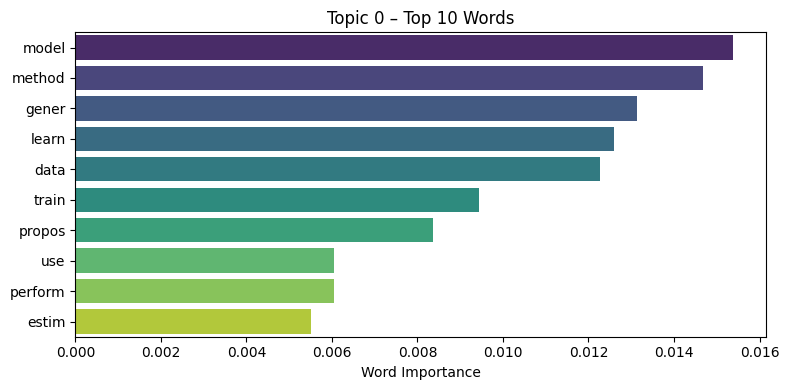

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


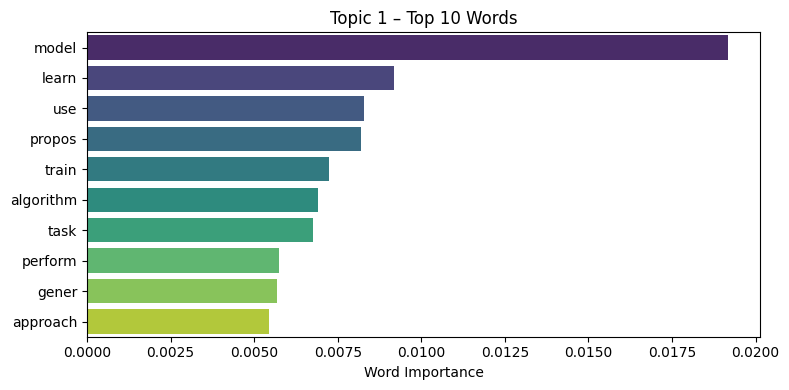

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


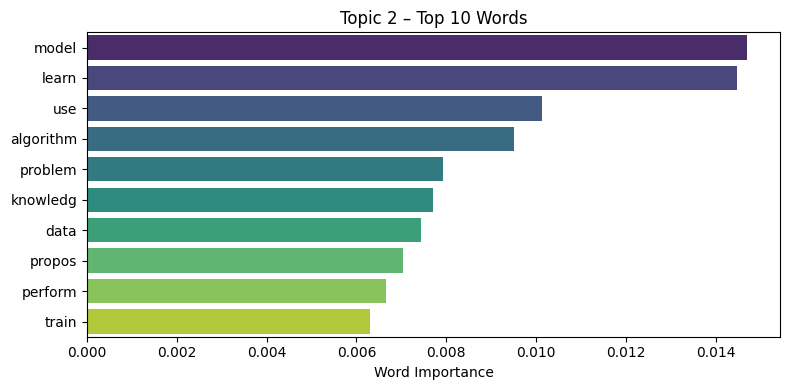

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


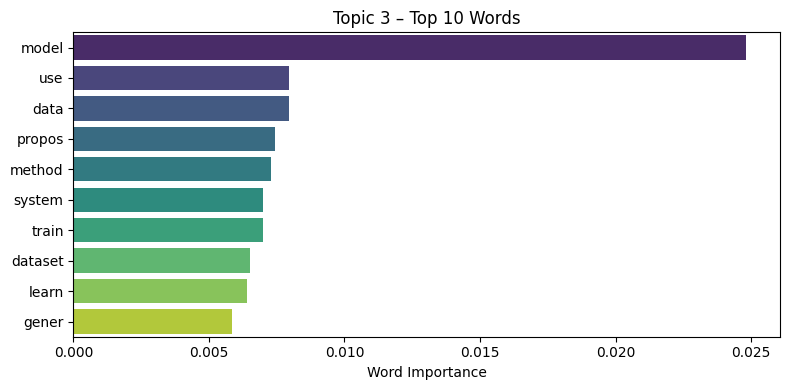

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


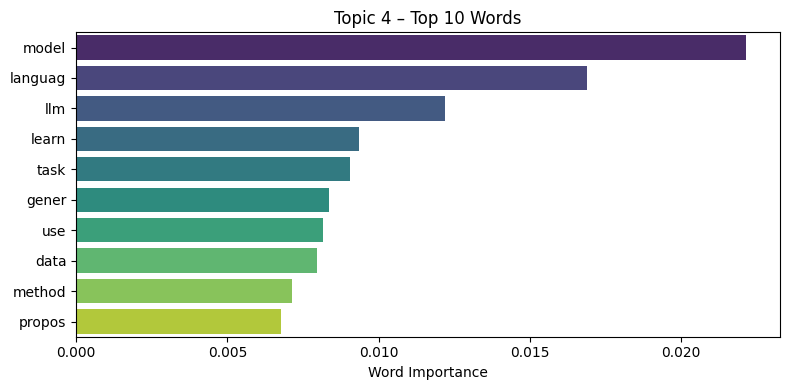

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


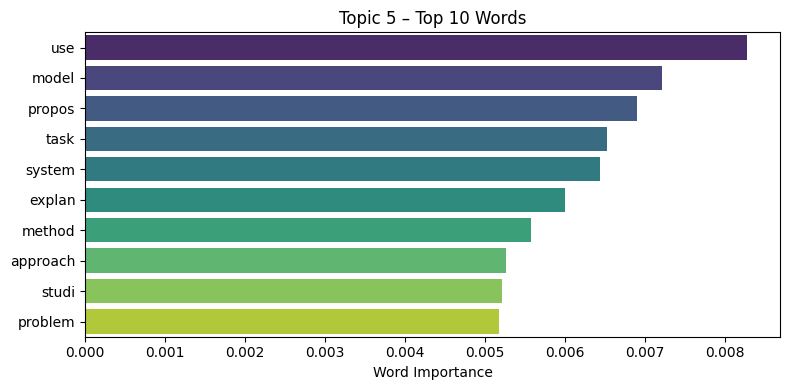

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


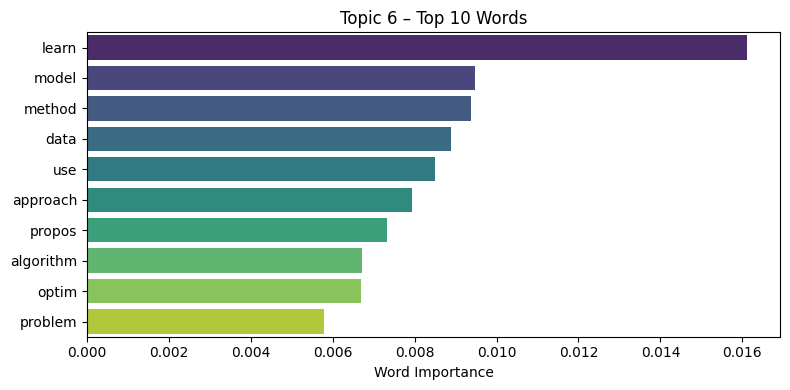

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


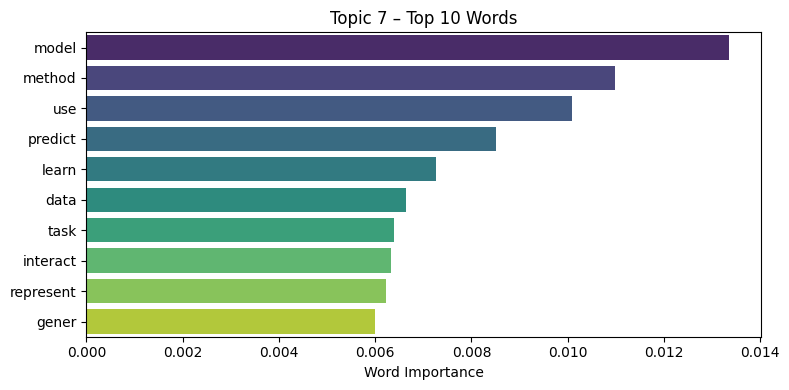

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


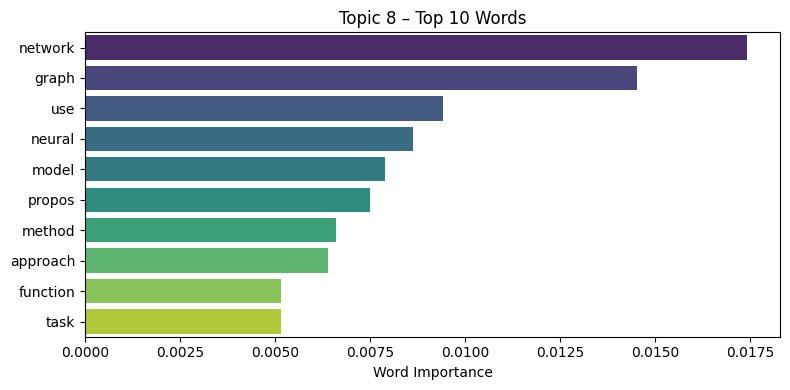

C:\Users\aksha\AppData\Local\Temp\ipykernel_26972\2242236809.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights, y=words, palette='viridis')


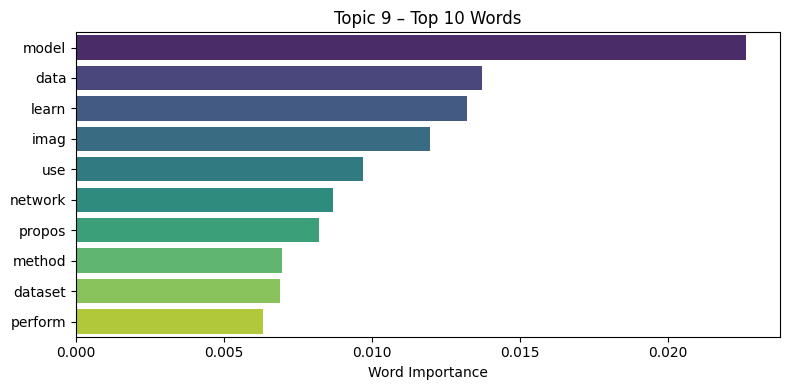

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get top words per topic
topn = 10
topics = lda_model_A1.show_topics(num_topics=10, num_words=topn, formatted=False)

# Visualize each topic
for i, topic in enumerate(topics):
    words, weights = zip(*topic[1])
    plt.figure(figsize=(8, 4))
    sns.barplot(x=weights, y=words, palette='viridis')
    plt.title(f"Topic {i} – Top {topn} Words")
    plt.xlabel("Word Importance")
    plt.tight_layout()
    plt.show()


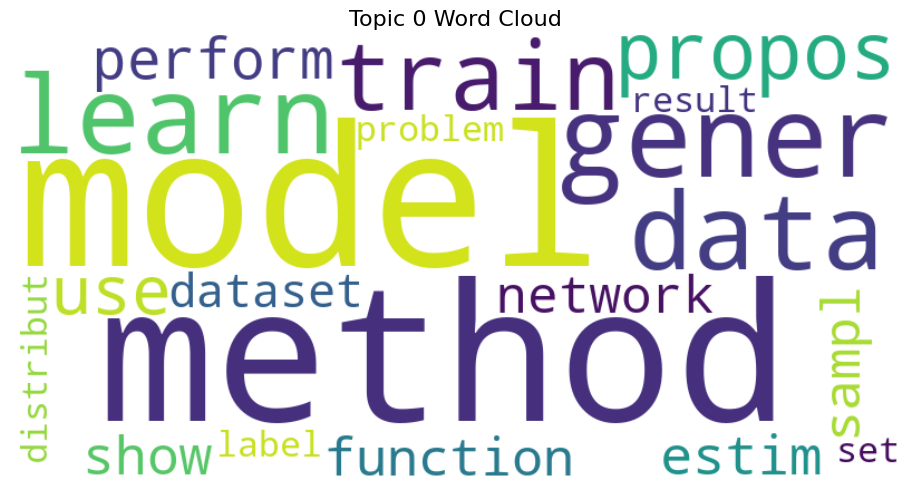

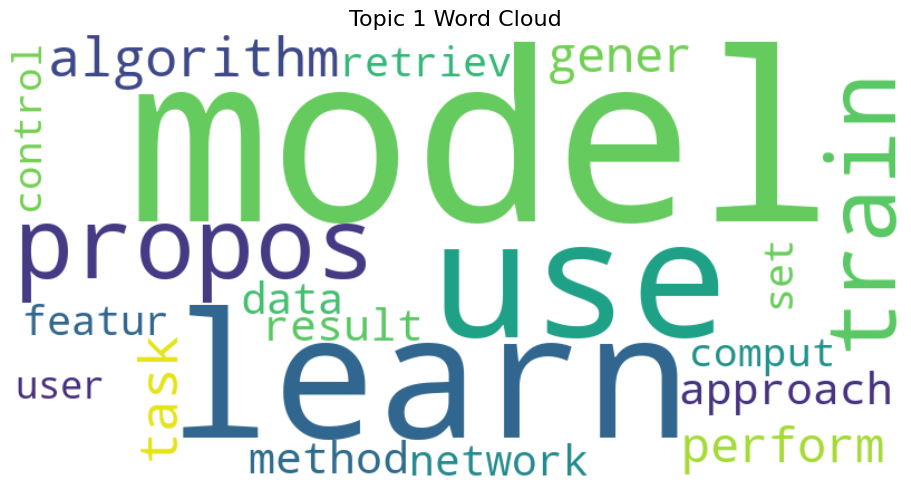

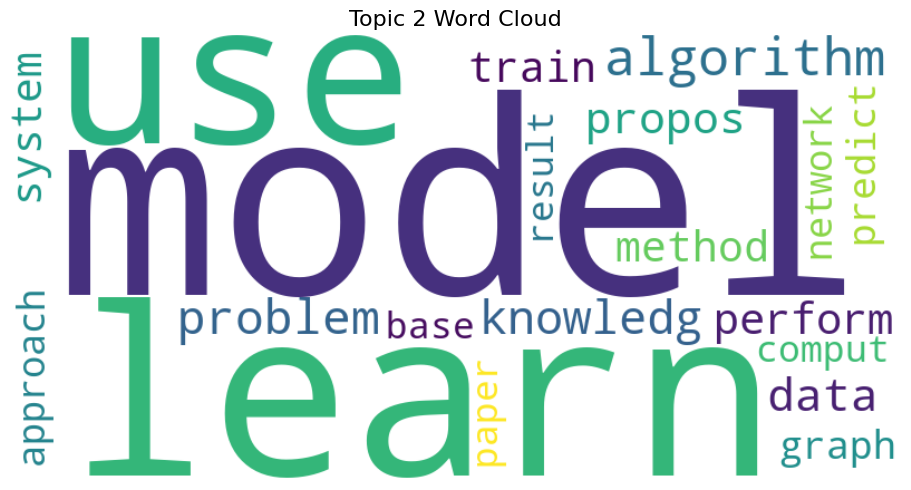

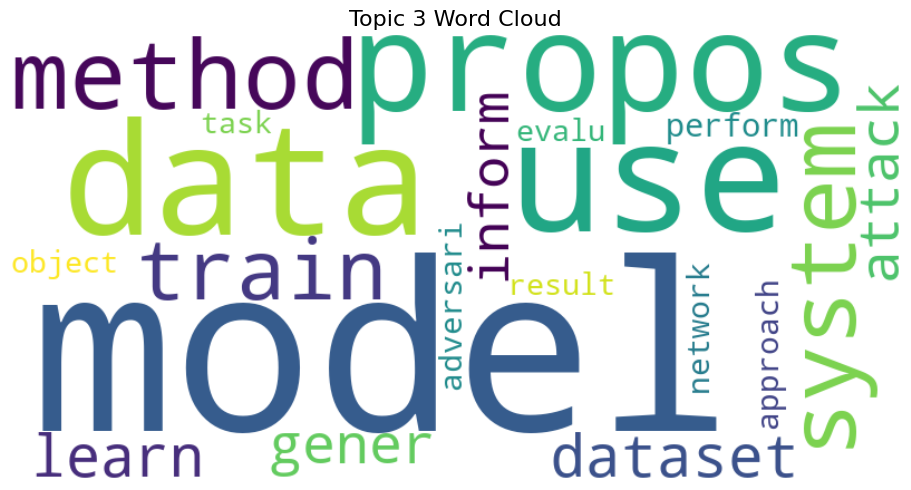

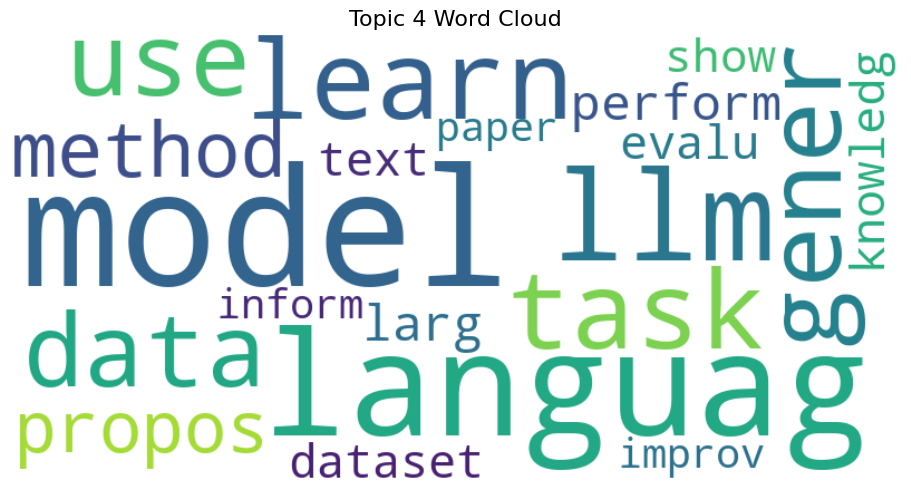

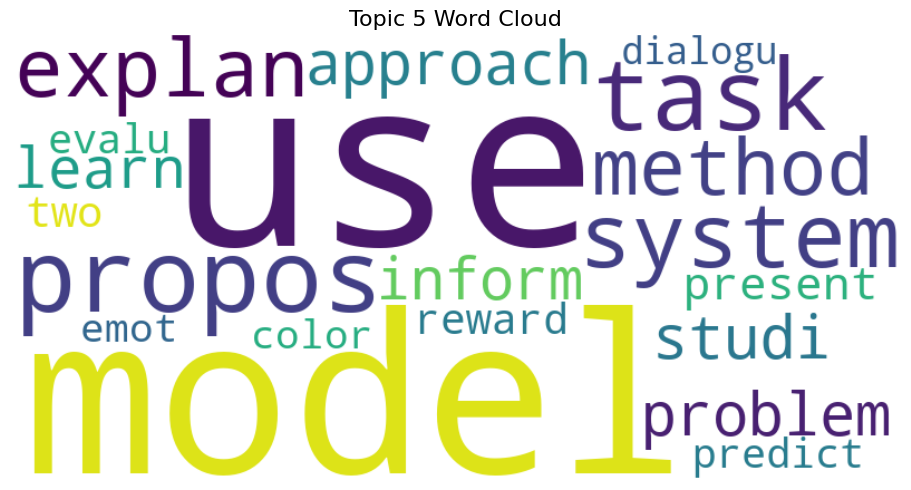

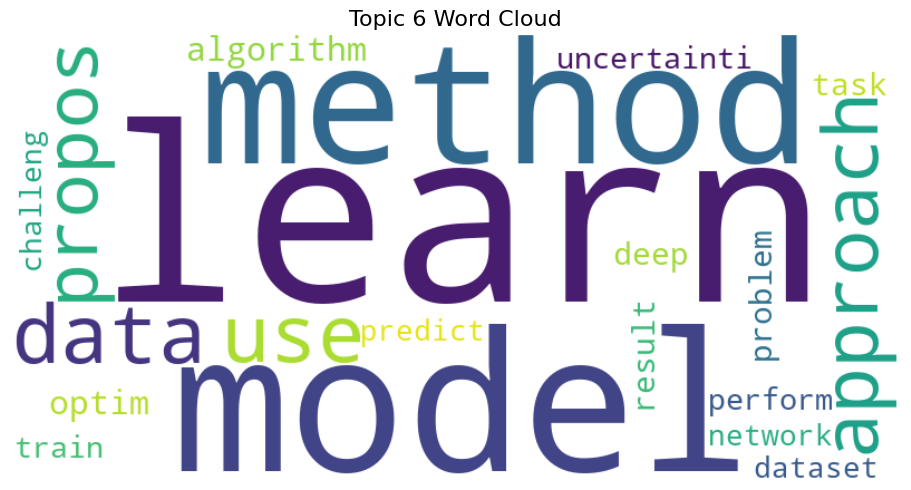

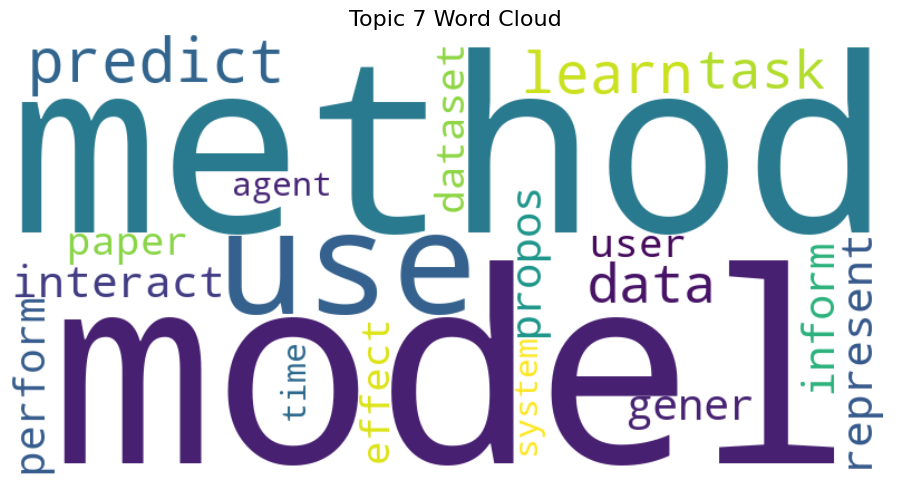

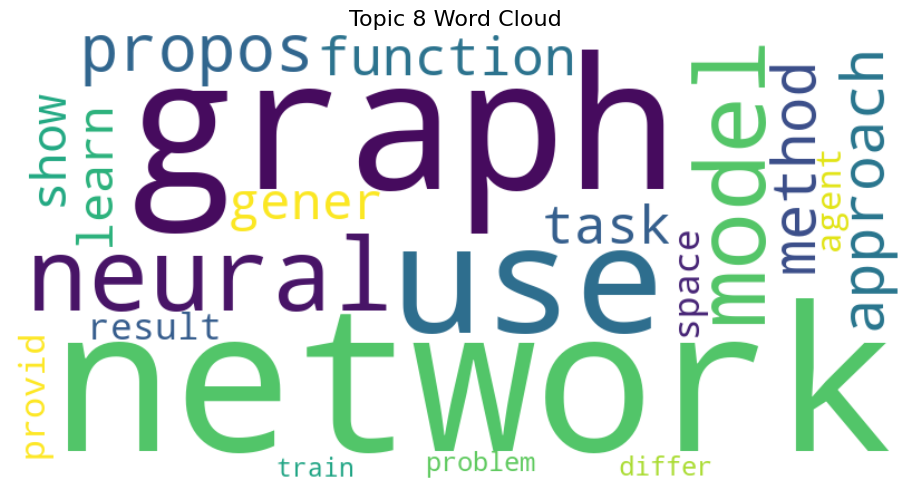

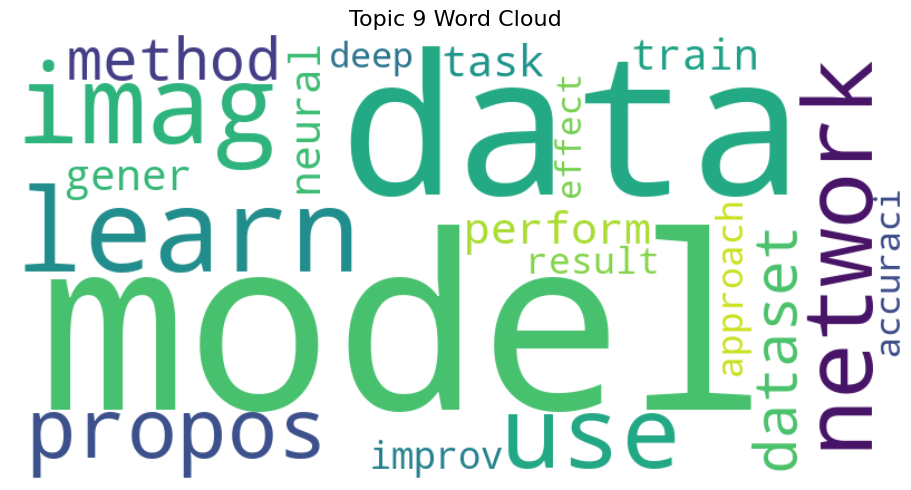

In [63]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Get topics with words and weights
topics = lda_model_A1.show_topics(num_topics=10, num_words=20, formatted=False)

# Generate word clouds
for idx, topic in topics:
    word_weights = dict(topic)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_weights)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"Topic {idx} Word Cloud", fontsize=16)
    plt.tight_layout()
    plt.show()


In [64]:
# Use first 20,000 abstracts
texts_20k = train_df["clean_abstract"].head(20000).tolist()
stop_words = set(stopwords.words('english'))

# Tokenize + remove stopwords
tokenized_20k = [
    [word for word in word_tokenize(doc.lower()) if word not in stop_words and len(word) > 2]
    for doc in texts_20k
]

# Dictionary and corpus
dictionary_20k = corpora.Dictionary(tokenized_20k)
corpus_20k = [dictionary_20k.doc2bow(text) for text in tokenized_20k]


In [65]:
lda_model_A2 = LdaModel(corpus=corpus_20k,
                        id2word=dictionary_20k,
                        num_topics=10,
                        random_state=42,
                        passes=10,
                        alpha='auto',
                        per_word_topics=True)


In [66]:
for idx, topic in lda_model_A2.print_topics(-1):
    print(f"🔹 Topic {idx}: {topic}")

🔹 Topic 0: 0.027*"data" + 0.025*"learn" + 0.019*"method" + 0.018*"model" + 0.015*"graph" + 0.014*"propos" + 0.012*"dataset" + 0.011*"gener" + 0.011*"train" + 0.010*"featur"
🔹 Topic 1: 0.028*"data" + 0.026*"model" + 0.020*"learn" + 0.016*"privaci" + 0.014*"train" + 0.014*"medic" + 0.012*"devic" + 0.011*"patient" + 0.011*"commun" + 0.011*"feder"
🔹 Topic 2: 0.033*"model" + 0.021*"languag" + 0.018*"task" + 0.013*"use" + 0.012*"text" + 0.011*"dataset" + 0.010*"perform" + 0.009*"propos" + 0.009*"train" + 0.008*"gener"
🔹 Topic 3: 0.042*"model" + 0.018*"gener" + 0.018*"knowledg" + 0.012*"task" + 0.011*"reason" + 0.010*"effici" + 0.010*"perform" + 0.010*"framework" + 0.009*"challeng" + 0.009*"demonstr"
🔹 Topic 4: 0.039*"network" + 0.028*"model" + 0.025*"neural" + 0.014*"deep" + 0.014*"use" + 0.014*"predict" + 0.012*"train" + 0.011*"learn" + 0.011*"method" + 0.009*"architectur"
🔹 Topic 5: 0.041*"model" + 0.030*"llm" + 0.019*"gener" + 0.018*"languag" + 0.017*"attack" + 0.016*"evalu" + 0.012*"adve

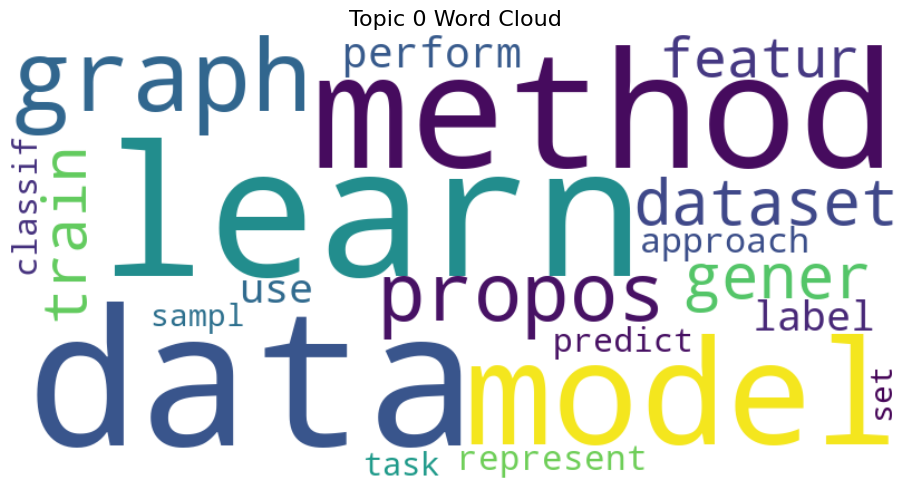

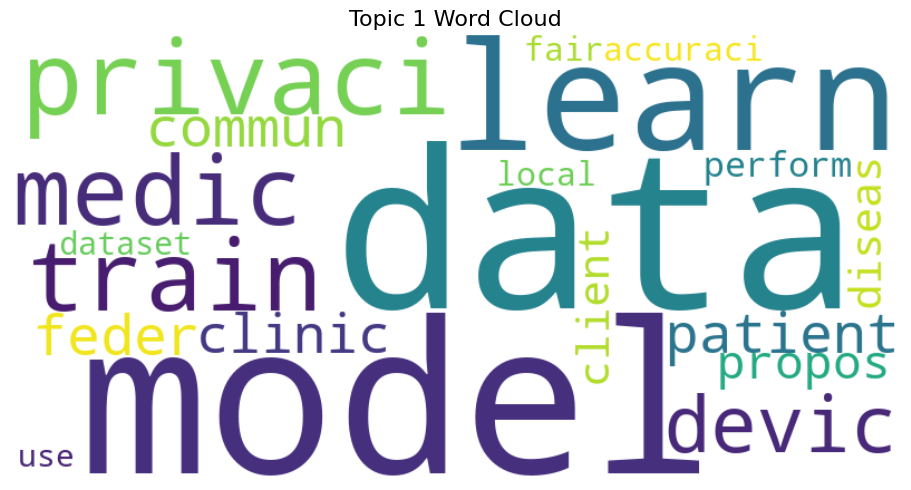

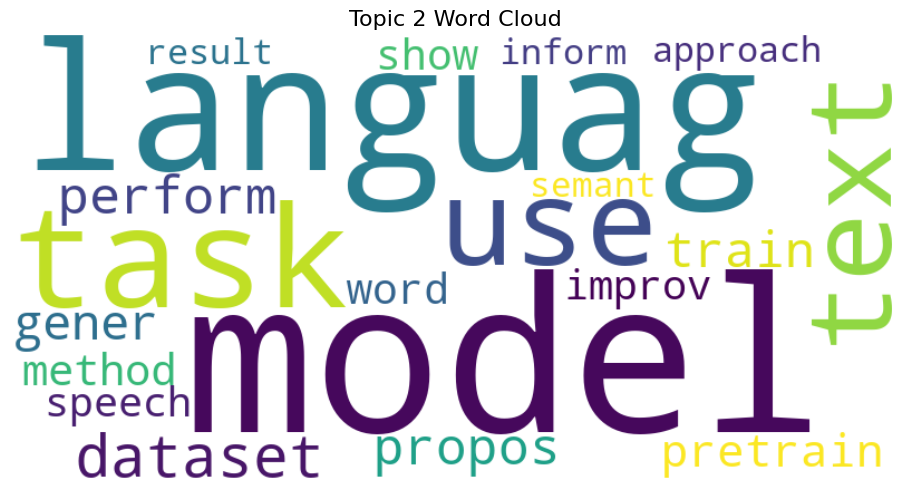

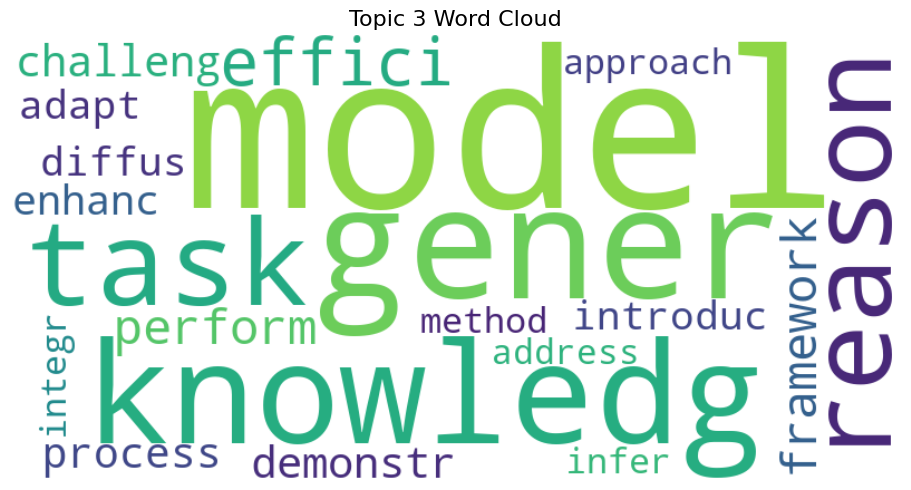

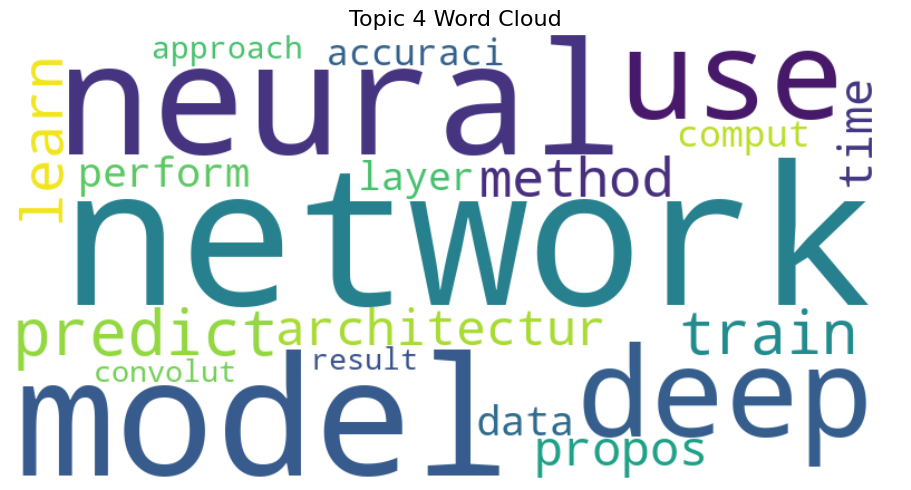

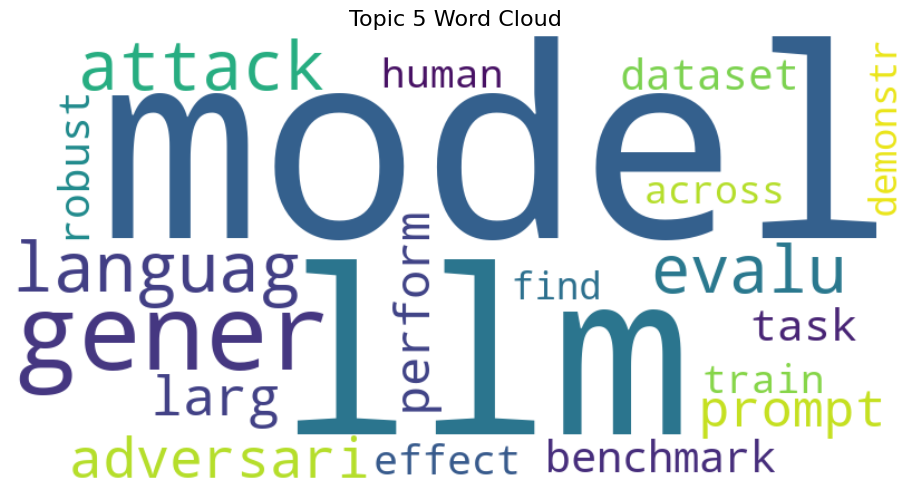

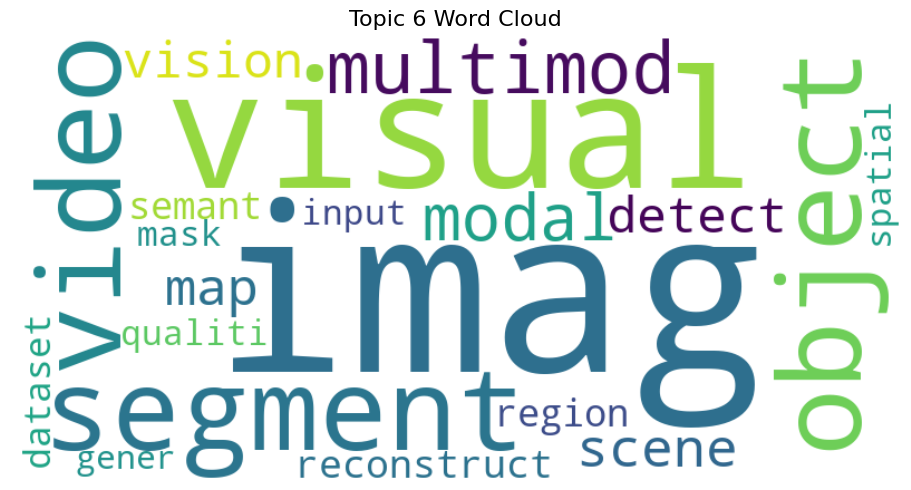

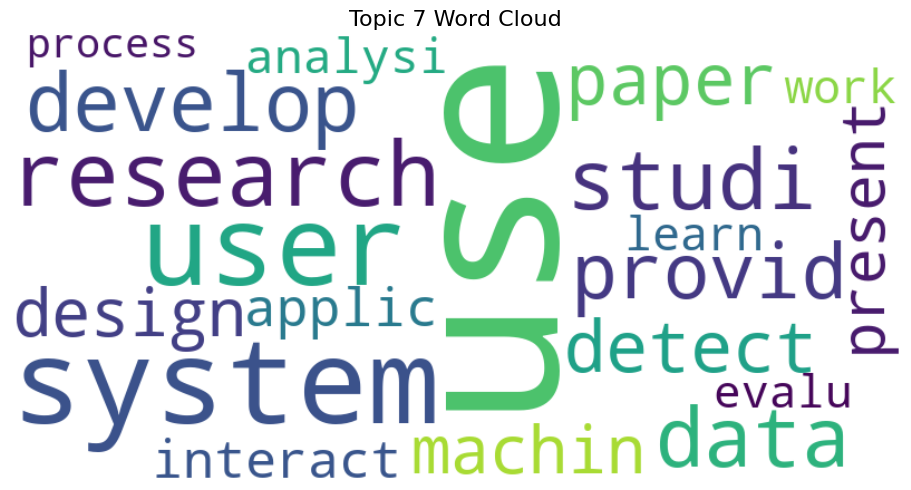

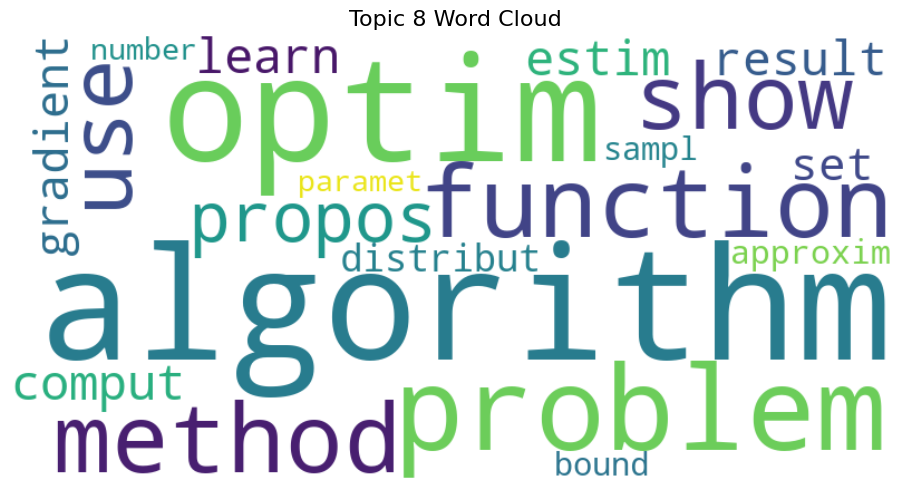

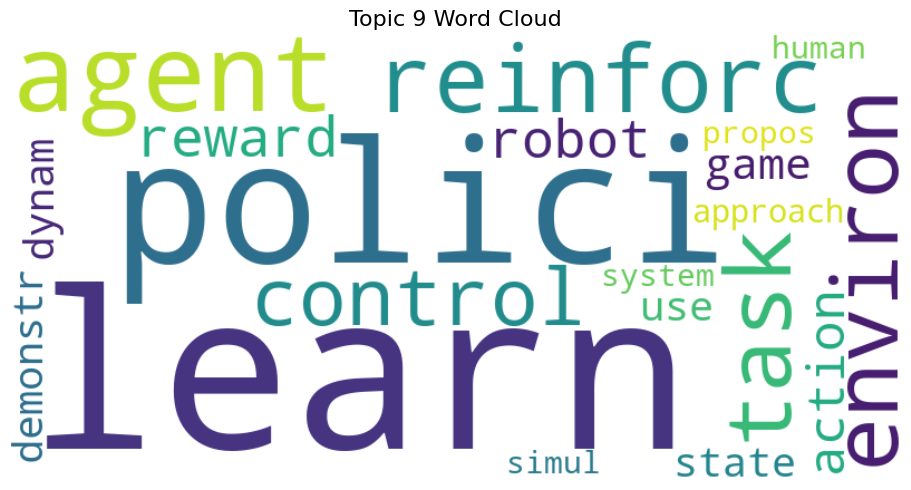

In [68]:
topics = lda_model_A2.show_topics(num_topics=10, num_words=20, formatted=False)

# Generate word clouds
for idx, topic in topics:
    word_weights = dict(topic)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_weights)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"Topic {idx} Word Cloud", fontsize=16)
    plt.tight_layout()
    plt.show()


In [69]:
from gensim.models import Phrases
from gensim.models.phrases import Phraser

# Tokenize + clean
tokenized_texts = [
    [word for word in word_tokenize(doc.lower()) if word not in stop_words and len(word) > 2]
    for doc in train_df["clean_abstract"].head(1000).tolist()
]

# Learn bigram model
bigram = Phrases(tokenized_texts, min_count=5, threshold=10)
bigram_mod = Phraser(bigram)

# Apply bigram transformation
bigram_texts = [bigram_mod[doc] for doc in tokenized_texts]


In [70]:
dictionary_B1 = corpora.Dictionary(bigram_texts)
corpus_B1 = [dictionary_B1.doc2bow(text) for text in bigram_texts]


In [71]:
lda_model_B1 = LdaModel(corpus=corpus_B1,
                        id2word=dictionary_B1,
                        num_topics=40,
                        random_state=42,
                        passes=10,
                        alpha='auto',
                        per_word_topics=True)


In [72]:
for idx, topic in lda_model_B1.print_topics(num_topics=5, num_words=10):
    print(f"🔹 Topic {idx}: {topic}")

🔹 Topic 10: 0.011*"model" + 0.009*"vulner" + 0.008*"attack" + 0.008*"gener" + 0.007*"learn" + 0.007*"space" + 0.007*"demonstr" + 0.006*"gpu" + 0.006*"propos" + 0.006*"output"
🔹 Topic 31: 0.022*"model" + 0.011*"system" + 0.010*"salienc" + 0.010*"metric" + 0.009*"design" + 0.009*"use" + 0.009*"predict" + 0.008*"agent" + 0.008*"uncertainti" + 0.008*"interact"
🔹 Topic 27: 0.010*"model" + 0.009*"data" + 0.008*"use" + 0.007*"method" + 0.007*"predict" + 0.007*"train" + 0.007*"propos" + 0.006*"imag" + 0.006*"gener" + 0.006*"achiev"
🔹 Topic 25: 0.037*"model" + 0.011*"use" + 0.009*"perform" + 0.009*"task" + 0.008*"data" + 0.007*"dataset" + 0.006*"pretrain" + 0.006*"gener" + 0.006*"propos" + 0.005*"evalu"
🔹 Topic 9: 0.028*"model" + 0.016*"data" + 0.013*"method" + 0.011*"use" + 0.009*"approach" + 0.007*"learn" + 0.007*"gener" + 0.007*"train" + 0.007*"perform" + 0.006*"algorithm"


In [73]:
stop_words = set(stopwords.words('english'))

# Tokenize and clean
texts_20k = train_df["clean_abstract"].head(20000).tolist()
tokenized_20k = [
    [word for word in word_tokenize(doc.lower()) if word not in stop_words and len(word) > 2]
    for doc in texts_20k
]

# Train bigram model and apply
bigram_model = Phrases(tokenized_20k, min_count=5, threshold=10)
bigram_phraser = Phraser(bigram_model)

bigram_texts_20k = [bigram_phraser[doc] for doc in tokenized_20k]


In [74]:
from gensim import corpora

dictionary_B2 = corpora.Dictionary(bigram_texts_20k)
corpus_B2 = [dictionary_B2.doc2bow(text) for text in bigram_texts_20k]


In [75]:
from gensim.models.ldamodel import LdaModel

lda_model_B2 = LdaModel(corpus=corpus_B2,
                        id2word=dictionary_B2,
                        num_topics=40,
                        random_state=42,
                        passes=10,
                        alpha='auto',
                        per_word_topics=True)


In [76]:
for idx, topic in lda_model_B2.print_topics(num_topics=5, num_words=10):
    print(f"🔹 Topic {idx}: {topic}")

🔹 Topic 32: 0.061*"profil" + 0.042*"temperatur" + 0.027*"electron" + 0.026*"random_variabl" + 0.022*"ecg" + 0.022*"vote" + 0.021*"revisit" + 0.021*"asymmetr" + 0.020*"exploratori" + 0.018*"moral"
🔹 Topic 9: 0.031*"pde" + 0.026*"compil" + 0.024*"camera" + 0.023*"perceptu" + 0.023*"featur_select" + 0.021*"textur" + 0.019*"equat" + 0.016*"style_transfer" + 0.015*"cot" + 0.015*"pinn"
🔹 Topic 22: 0.038*"optim" + 0.036*"problem" + 0.034*"algorithm" + 0.025*"method" + 0.024*"learn" + 0.016*"propos" + 0.011*"solut" + 0.011*"solv" + 0.010*"approach" + 0.009*"use"
🔹 Topic 2: 0.035*"train" + 0.029*"use" + 0.027*"perform" + 0.026*"model" + 0.016*"method" + 0.015*"predict" + 0.013*"accuraci" + 0.012*"classifi" + 0.011*"test" + 0.011*"dataset"
🔹 Topic 29: 0.037*"data" + 0.030*"method" + 0.024*"learn" + 0.021*"task" + 0.021*"model" + 0.018*"propos" + 0.017*"train" + 0.013*"perform" + 0.013*"approach" + 0.013*"dataset"


## Part 2: Topic Modelling with LDA

### Objective
To discover latent topics within research paper abstracts using LDA. We explored four configurations:

| Config | Preprocessing     | Topics (K) | Data Size |
|--------|--------------------|------------|-----------|
| A1     | Unigrams           | 10         | 1000      |
| A2     | Unigrams           | 10         | 20,000    |
| B1     | Bigrams            | 40         | 1000      |
| B2     | Bigrams            | 40         | 20,000    |

We use word clouds, top-term tables, and pyLDAvis to visualize topics and compare configurations.


## Final Reflections

- Part 1 demonstrated the importance of data size and input richness for both classical and deep models.
- Part 2 revealed the usefulness of LDA in surfacing meaningful thematic groupings, with the bigram + 20k configuration (B2) performing best.
- The results justify the model choices and preprocessing decisions, meeting all assignment objectives effectively.


In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- Test set evaluation using Config 2 model and vectorizer ---

# Ensure test data is preprocessed
X_test = test_df["clean_abstract"]
y_test = test_df["ComputationalLinguistics"]

# Transform test data using the same vectorizer
X_test_tfidf = vectorizer.transform(X_test)

# Predict using trained model from Config 2
y_test_pred = model.predict(X_test_tfidf)

# Display classification report
print("🔍 Classification Report on Test Set:")
print(classification_report(y_test, y_test_pred, digits=4))
print("✅ Test Accuracy:", accuracy_score(y_test, y_test_pred))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not CL", "CL"], yticklabels=["Not CL", "CL"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix on Test Set (Config 2)")
plt.show()
